# 01 — Exploratory Data Analysis (EDA)

**Goal:** Load and clean the IBM Telco dataset, then explore churn patterns across customer subgroups.

This notebook reproduces the descriptive statistics reported in the proposal (F1 Appendix) and
saves figures for the final report.

**Outputs:**
- `../data/processed/telco_clean.csv` (cleaned data used by later notebooks)
- `../results/figures/churn_by_contract.png`
- `../results/figures/churn_by_tenure.png`
- `../results/tables/churn_by_category.csv`


## Setup — imports and reproducibility

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Reproducibility — fix the random seed everywhere
SEED = 42
np.random.seed(SEED)

# Consistent plot style
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

# Colour palette used across the whole project
NAVY, BLUE, TEAL, CORAL = '#0A2540', '#1C7293', '#00A896', '#F4845F'


## 1. Load the raw data

In [2]:
df = pd.read_csv('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(f'Raw shape: {df.shape}')          # expect (7043, 21)
df.head()


Raw shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Clean the data

`TotalCharges` is stored as text and has 11 blank entries — these belong to brand-new customers
whose `tenure` is 0. We convert the column to numeric and drop those 11 rows, leaving 7,032 records.
We also create a binary target `ChurnBinary` (1 = churned, 0 = retained).

In [3]:
# TotalCharges is object type with blanks -> coerce to numeric (blanks become NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f'Missing TotalCharges: {df["TotalCharges"].isna().sum()}')   # expect 11

# Drop the 11 rows and reset the index
df = df.dropna(subset=['TotalCharges']).reset_index(drop=True)

# Binary target
df['ChurnBinary'] = (df['Churn'] == 'Yes').astype(int)

print(f'Clean shape: {df.shape}')                      # expect (7032, 22)
print(f'Churn rate: {df["ChurnBinary"].mean()*100:.2f}%')   # expect 26.58%
print(f'Class ratio: {(1-df["ChurnBinary"].mean())/df["ChurnBinary"].mean():.2f} : 1')


Missing TotalCharges: 11
Clean shape: (7032, 22)
Churn rate: 26.58%
Class ratio: 2.76 : 1


## 3. Numeric summary (proposal Table 2)

In [4]:
df[['tenure','MonthlyCharges','TotalCharges']].describe().round(2)


,tenure,MonthlyCharges,TotalCharges
count,7032.00,7032.00,7032.00
mean,32.42,64.80,2283.30
std,24.55,30.09,2266.77
min,1.00,18.25,18.80
25%,9.00,35.59,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.86,3794.74
max,72.00,118.75,8684.80


## 4. Churn rate by category

This is the key evidence for the whole project: churn varies enormously across subgroups,
which motivates segment-specific modelling.

In [5]:
for col in ['Contract', 'InternetService', 'PaymentMethod']:
    print(f'--- {col} ---')
    summary = df.groupby(col)['ChurnBinary'].agg(['count', 'mean'])
    summary['mean'] = (summary['mean']*100).round(2)
    summary.columns = ['Customers', 'Churn %']
    print(summary, '\n')


--- Contract ---
                Customers  Churn %
Contract                          
Month-to-month       3875    42.71
One year             1472    11.28
Two year             1685     2.85 

--- InternetService ---
                 Customers  Churn %
InternetService                    
DSL                   2416    19.00
Fiber optic           3096    41.89
No                    1520     7.43 

--- PaymentMethod ---
                           Customers  Churn %
PaymentMethod                                
Bank transfer (automatic)       1542    16.73
Credit card (automatic)         1521    15.25
Electronic check                2365    45.29
Mailed check                    1604    19.20 



## 5. Figure — Churn rate by contract type

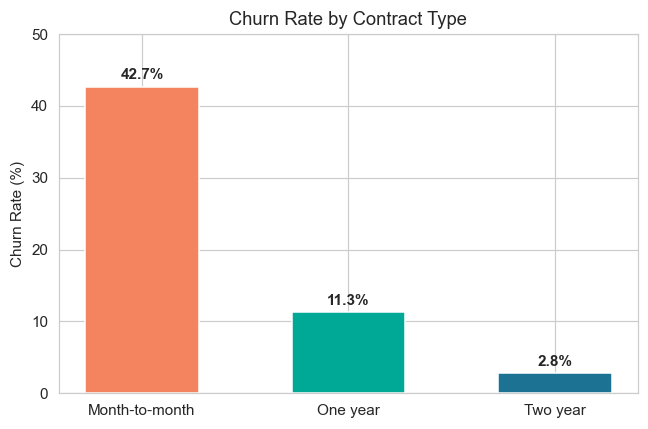

In [6]:
contract_order = ['Month-to-month', 'One year', 'Two year']
rates = [df[df['Contract']==c]['ChurnBinary'].mean()*100 for c in contract_order]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(contract_order, rates, color=[CORAL, TEAL, BLUE], width=0.55)
ax.set_ylabel('Churn Rate (%)')
ax.set_title('Churn Rate by Contract Type')
ax.set_ylim(0, 50)
for b, r in zip(bars, rates):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+1, f'{r:.1f}%',
            ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('../results/figures/churn_by_contract.png', dpi=200, bbox_inches='tight')
plt.show()


## 6. Figure — Churn rate by tenure band

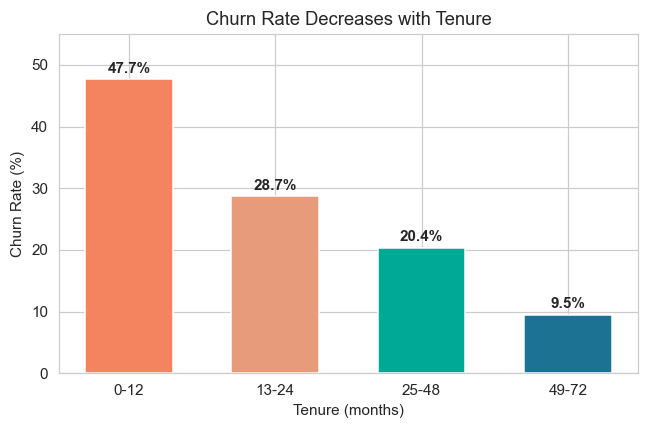

In [7]:
bins = [0, 12, 24, 48, 72]
labels = ['0-12', '13-24', '25-48', '49-72']
df['TenureBand'] = pd.cut(df['tenure'], bins=bins, labels=labels, include_lowest=True)
band_rates = df.groupby('TenureBand')['ChurnBinary'].mean()*100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, band_rates.values, color=[CORAL, '#E89B7A', TEAL, BLUE], width=0.6)
ax.set_ylabel('Churn Rate (%)')
ax.set_xlabel('Tenure (months)')
ax.set_title('Churn Rate Decreases with Tenure')
ax.set_ylim(0, 55)
for b, r in zip(bars, band_rates.values):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+1, f'{r:.1f}%',
            ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('../results/figures/churn_by_tenure.png', dpi=200, bbox_inches='tight')
plt.show()


## 7. Save cleaned data and summary table

In [8]:
# Save table for the report
cat_summary = []
for col in ['Contract', 'InternetService', 'PaymentMethod']:
    g = df.groupby(col)['ChurnBinary'].agg(['count','mean']).reset_index()
    g.columns = ['Category', 'Customers', 'ChurnRate']
    g['Variable'] = col
    cat_summary.append(g)
pd.concat(cat_summary)[['Variable','Category','Customers','ChurnRate']].to_csv(
    '../results/tables/churn_by_category.csv', index=False)

# Save cleaned dataset for the next notebooks
df.to_csv('../data/processed/telco_clean.csv', index=False)
print('Saved: telco_clean.csv, churn_by_category.csv, 2 figures')


Saved: telco_clean.csv, churn_by_category.csv, 2 figures
